In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# df = pd.read_csv('logs/2025-07-24-09-58-47_inferences.csv')
# df = pd.read_csv('logs/2025-07-24-11-06-21_inferences.csv')
df = pd.read_csv('logs/2025-07-24-11-27-59_inferences.csv')
df.describe()

,targets_100,preds_100,mae_100,mse_100,mre_100,targets_125,preds_125,mae_125,mse_125,mre_125,...,targets_3150,preds_3150,mae_3150,mse_3150,mre_3150,targets_4000,preds_4000,mae_4000,mse_4000,mre_4000
count,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,3.282500e+04,3.282500e+04,32825.000000,...,32825.000000,32825.000000,3.282500e+04,3.282500e+04,32825.000000,32825.000000,32825.000000,32825.000000,3.282500e+04,32825.000000
mean,0.732642,0.735020,0.011864,0.000311,1.642489,0.723184,0.725317,1.214229e-02,3.250517e-04,1.700224,...,0.182637,0.166705,6.435313e-02,6.980437e-03,43.111495,0.174357,0.154986,0.066517,7.538452e-03,49.327992
std,0.017481,0.000006,0.013058,0.000857,1.870730,0.017903,0.000012,1.332749e-02,9.219662e-04,1.911915,...,0.082017,0.000004,5.328414e-02,1.250551e-02,52.640214,0.084637,0.000001,0.055803,1.366769e-02,68.936284
min,0.616302,0.733872,0.000000,0.000000,0.000000,0.628035,0.724495,1.192093e-07,1.421085e-14,0.000016,...,0.020281,0.166133,4.023314e-07,1.618705e-13,0.000241,0.013658,0.154811,0.000002,3.250955e-12,0.001163
25%,0.726306,0.735020,0.003705,0.000014,0.504274,0.716494,0.725317,3.801346e-03,1.445023e-05,0.524597,...,0.121550,0.166705,2.549368e-02,6.499278e-04,15.227407,0.111250,0.154986,0.025950,6.733855e-04,16.690315
50%,0.735249,0.735020,0.008058,0.000065,1.094848,0.725626,0.725317,8.292973e-03,6.877340e-05,1.140549,...,0.169228,0.166705,5.269252e-02,2.776501e-03,30.874223,0.160941,0.154986,0.053643,2.877529e-03,33.381549
75%,0.742659,0.735020,0.014890,0.000222,2.018777,0.733254,0.725317,1.535839e-02,2.358801e-04,2.106826,...,0.231034,0.166705,8.729595e-02,7.620583e-03,50.007618,0.223881,0.154986,0.089922,8.086027e-03,53.535472
max,0.855422,0.735211,0.120402,0.014497,19.262943,0.862471,0.727407,1.371543e-01,1.881130e-02,15.902479,...,0.600147,0.166742,4.334422e-01,1.878721e-01,721.966759,0.593958,0.155084,0.438972,1.926961e-01,1034.802512


In [4]:
frequencies = [100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000]
frequencies_str = ['100','125','160','200','250','315','400','500','630','800','1000','1250','1600','2000','2500','3150','4000']
losses = ['mae', 'mse', 'mre']

## Comparing Predictions

In [5]:
pred = df[[f'preds_{freq}' for freq in frequencies]]
pred.describe()

,preds_100,preds_125,preds_160,preds_200,preds_250,preds_315,preds_400,preds_500,preds_630,preds_800,preds_1000,preds_1250,preds_1600,preds_2000,preds_2500,preds_3150,preds_4000
count,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000
mean,0.735020,0.725317,0.709657,0.691776,0.671669,0.653003,0.623144,0.524852,0.406572,0.366121,0.325069,0.298669,0.251720,0.195732,0.174883,0.166705,0.154986
std,0.000006,0.000012,0.000002,0.000011,0.000010,0.000007,0.000004,0.000010,0.000012,0.000008,0.000010,0.000004,0.000007,0.000004,0.000009,0.000004,0.000001
min,0.733872,0.724495,0.709386,0.689932,0.671669,0.652045,0.622433,0.524463,0.404364,0.366121,0.323352,0.298055,0.250586,0.195073,0.174558,0.166133,0.154811
25%,0.735020,0.725317,0.709657,0.691776,0.671669,0.653003,0.623144,0.524852,0.406572,0.366121,0.325069,0.298669,0.251720,0.195732,0.174883,0.166705,0.154986
50%,0.735020,0.725317,0.709657,0.691776,0.671669,0.653003,0.623144,0.524852,0.406572,0.366121,0.325069,0.298669,0.251720,0.195732,0.174883,0.166705,0.154986
75%,0.735020,0.725317,0.709657,0.691776,0.671669,0.653003,0.623144,0.524852,0.406572,0.366121,0.325069,0.298669,0.251720,0.195732,0.174883,0.166705,0.154986
max,0.735211,0.727407,0.709980,0.692723,0.673145,0.653689,0.623144,0.526566,0.406572,0.367528,0.325371,0.298686,0.252000,0.196030,0.176419,0.166742,0.155084


In [6]:
for freq in frequencies:
    print(f"Number of unique values for frequency {freq}: {pred[f'preds_{freq}'].nunique()}")

Number of unique values for frequency 100: 4
Number of unique values for frequency 125: 4
Number of unique values for frequency 160: 4
Number of unique values for frequency 200: 4
Number of unique values for frequency 250: 4
Number of unique values for frequency 315: 4
Number of unique values for frequency 400: 4
Number of unique values for frequency 500: 4
Number of unique values for frequency 630: 4
Number of unique values for frequency 800: 4
Number of unique values for frequency 1000: 4
Number of unique values for frequency 1250: 4
Number of unique values for frequency 1600: 4
Number of unique values for frequency 2000: 4
Number of unique values for frequency 2500: 4
Number of unique values for frequency 3150: 4
Number of unique values for frequency 4000: 4


## Plotting Losses by Frequency

In [16]:
mean_mae_by_freq = np.zeros(len(frequencies))
mean_mse_by_freq = np.zeros(len(frequencies))
mean_mre_by_freq = np.zeros(len(frequencies))
for i, freq in enumerate(frequencies):
    mean_mae_by_freq[i] = df[f'mae_{freq}'].mean()
    mean_mse_by_freq[i] = df[f'mse_{freq}'].mean()
    mean_mre_by_freq[i] = df[f'mre_{freq}'].mean()

mean_mae = np.mean(mean_mae_by_freq)
mean_mse = np.mean(mean_mse_by_freq)
mean_mre = np.mean(mean_mre_by_freq)

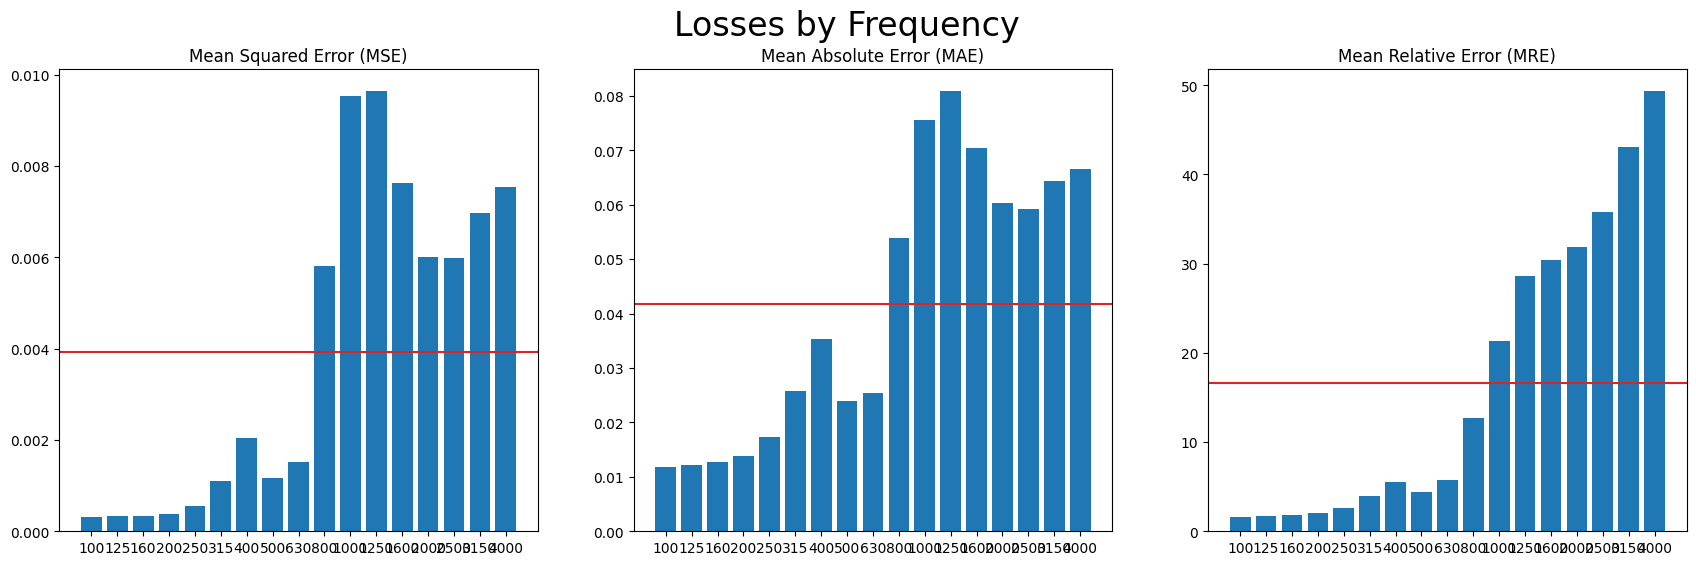

In [31]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21,6))

f.suptitle('Losses by Frequency', fontsize=24)
ax1.bar(frequencies_str, mean_mse_by_freq)
ax1.set_title('Mean Squared Error (MSE)')
ax1.axhline(mean_mse, color='tab:red', label='Mean MSE')
ax2.bar(frequencies_str, mean_mae_by_freq)
ax2.set_title('Mean Absolute Error (MAE)')
ax2.axhline(mean_mae, color='tab:red', label='Mean MAE')
ax3.bar(frequencies_str, mean_mre_by_freq)
ax3.set_title('Mean Relative Error (MRE)')
ax3.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()

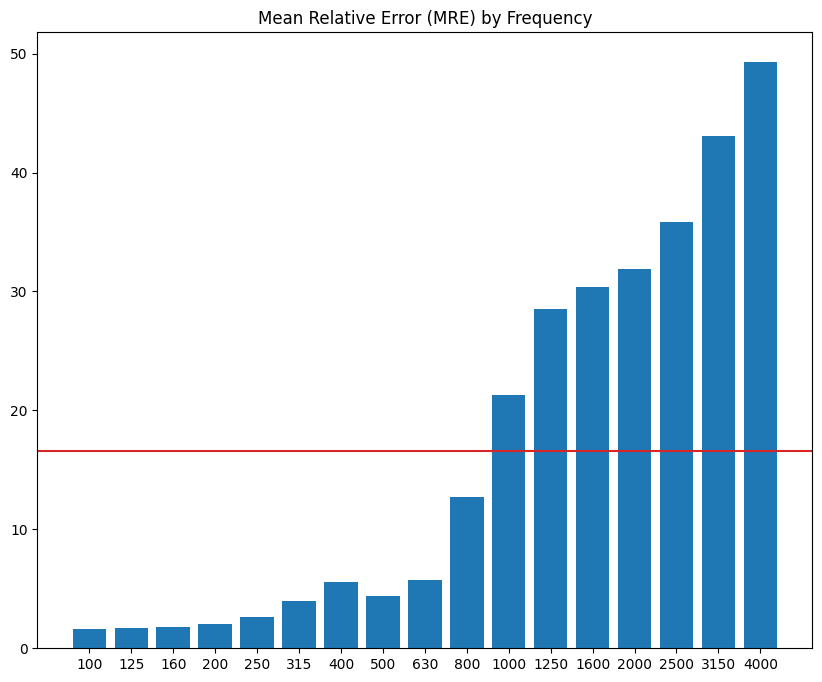

In [30]:
f, ax1 = plt.subplots(1, 1, figsize=(10,8))

ax1.bar(frequencies_str, mean_mre_by_freq)
ax1.set_title('Mean Relative Error (MRE) by Frequency')
ax1.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()